# Pattern analysis: divergences, channels/rectangles, and PIP pattern mining

Three new pattern families are tested on BTCUSDT daily and hourly data (2018 → Oct 2026):

1. **RSI and MACD divergences** (`divergences.py`)
2. **Rectangles, channels and broadening formations** (`triangles_wedges.py`, `PARALLEL_SHAPES`)
3. **PIP pattern miner**: lets the data pick the shapes (`pip_pattern_miner.py`, now using scikit-learn)

**Method.** Every pattern is recorded on the first bar where it is complete, and we "enter" at that bar's close, so no future data is used.
We measure the forward return in the pattern's direction and compare it with entering on random bars (the *excess*).
The data is split into **in-sample (before 2024)** and **recent (2024 onward)**. A pattern only counts if it beats random in both.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from pattern_backtest import load_ohlc, collect_events, forward_returns, evaluate, summarize, DEFAULTS
from divergences import find_divergences, rsi, macd_hist
from triangles_wedges import find_triangles_wedges, PARALLEL_SHAPES
from pip_pattern_miner import PIPPatternMiner
from perceptually_important import find_pips

TEST_START = pd.Timestamp('2024-01-01')

# Chart style: light surface, recessive grid, fixed categorical order
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
plt.rcParams.update({
    'figure.figsize': (11, 4.5), 'figure.dpi': 110, 'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7', 'axes.grid': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.spines.top': False,
    'axes.spines.right': False, 'lines.linewidth': 1.6, 'font.size': 10,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.axisbelow': True,
})
pd.set_option('display.width', 200)

daily = load_ohlc('BTCUSDT86400.csv')
hourly = load_ohlc('BTCUSDT3600.csv')
print(f'Daily:  {len(daily):>6} bars  {daily.index[0].date()} -> {daily.index[-1].date()}')
print(f'Hourly: {len(hourly):>6} bars  {hourly.index[0].date()} -> {hourly.index[-1].date()}')

Daily:    3207 bars  2018-01-02 -> 2026-10-13
Hourly:  76840 bars  2018-01-08 -> 2026-10-14


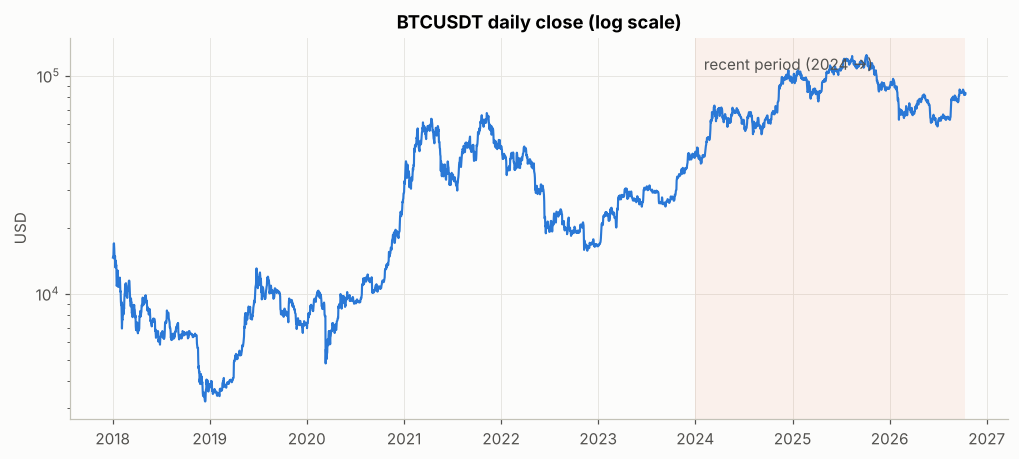

In [2]:
fig, ax = plt.subplots()
ax.plot(daily.index, daily['close'], color=BLUE, lw=1.4)
ax.axvspan(TEST_START, daily.index[-1], color=ORANGE, alpha=0.08, lw=0)
ax.text(TEST_START, daily['close'].max(), '  recent period (2024 →)', va='top', color='#52514e')
ax.set_yscale('log')
ax.set_title('BTCUSDT daily close (log scale)')
ax.set_ylabel('USD')
plt.show()

In [3]:
# Run every detector once per timeframe and score it in both periods
def run(ohlc):
    tf = 'daily' if ohlc is daily else 'hourly'
    cfg = DEFAULTS[tf]
    events = collect_events(ohlc, cfg['order'], cfg['tri_lookback'])
    fwd = forward_returns(ohlc['close'].to_numpy(), cfg['horizons'])
    recent = np.asarray(ohlc.index >= TEST_START)
    res = pd.concat([evaluate(events, fwd, ~recent, 'in_sample'),
                     evaluate(events, fwd, recent, 'recent')], ignore_index=True)
    return events, res, cfg

ev_d, res_d, cfg_d = run(daily)
ev_h, res_h, cfg_h = run(hourly)
sum_d = summarize(res_d, horizon=5, min_n=8, alpha=0.1)
sum_h = summarize(res_h, horizon=24, min_n=8, alpha=0.1)

def show(summary, prefixes):
    keep = summary[summary.index.str.startswith(prefixes)]
    return keep.round({'is_hit_rate': 2, 'is_excess_pct': 2, 'is_p_value': 3,
                       'recent_hit_rate': 2, 'recent_excess_pct': 2, 'recent_p_value': 3})

## 1. RSI and MACD divergences

A **regular** divergence is when price makes a new extreme but the indicator doesn't: a lower low in price with a higher low in RSI is bullish.
A **hidden** divergence is the reverse and is read as trend continuation.
Swings come from the repo's rolling-window extremes (`order` = 3 days / 6 hours), and the signal fires when the second swing is confirmed.

An example from the recent period:

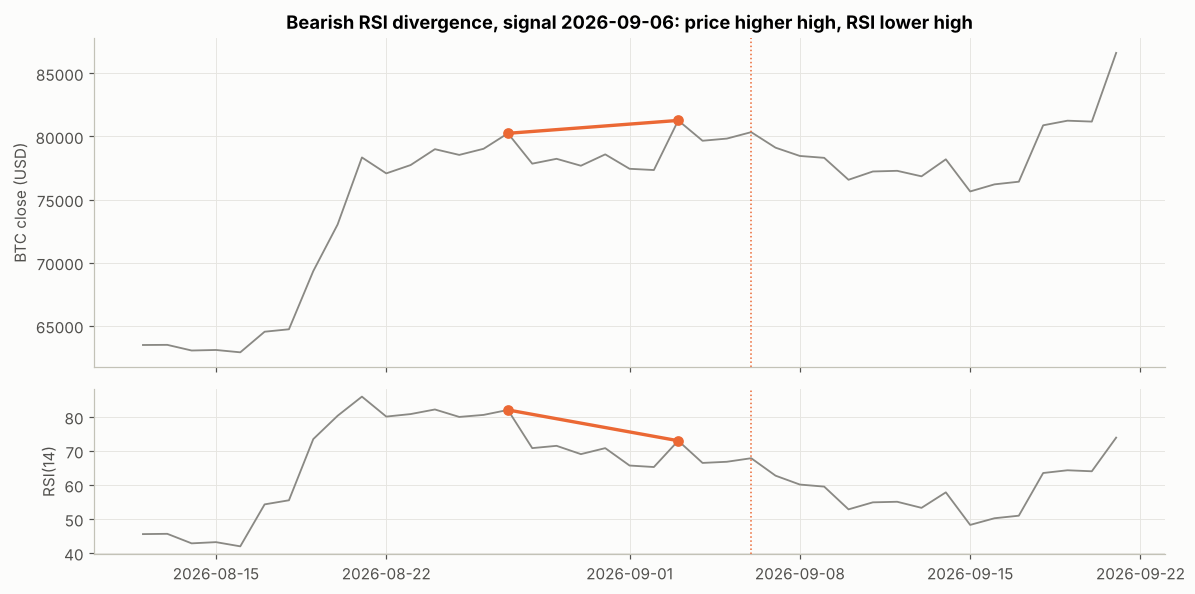

In [4]:
close_d = daily['close'].to_numpy()
rsi_d = rsi(close_d)
divs = find_divergences(np.log(close_d), rsi_d, order=3)
recent_divs = [d for d in divs if daily.index[d.conf_i] >= TEST_START and d.kind == 'bear']
d = recent_divs[-1]

pad = 15
s, e = max(d.ext1_i - pad, 0), min(d.conf_i + pad, len(daily) - 1)
idx = daily.index[s:e + 1]
fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(11, 5.5), gridspec_kw={'height_ratios': [2, 1]})
a1.plot(idx, close_d[s:e + 1], color=GRAY, lw=1.2)
a1.plot(daily.index[[d.ext1_i, d.ext2_i]], close_d[[d.ext1_i, d.ext2_i]], color=ORANGE, lw=2.2, marker='o', ms=6)
a1.axvline(daily.index[d.conf_i], color=ORANGE, ls=':', lw=1)
a1.set_title(f'Bearish RSI divergence, signal {daily.index[d.conf_i].date()}: price higher high, RSI lower high')
a1.set_ylabel('BTC close (USD)')
a2.plot(idx, rsi_d[s:e + 1], color=GRAY, lw=1.2)
a2.plot(daily.index[[d.ext1_i, d.ext2_i]], [d.ind1, d.ind2], color=ORANGE, lw=2.2, marker='o', ms=6)
a2.axvline(daily.index[d.conf_i], color=ORANGE, ls=':', lw=1)
a2.set_ylabel('RSI(14)')
plt.tight_layout(); plt.show()

### Divergence results: daily, 5 days after the signal

In [5]:
show(sum_d, ('rsi_', 'macd_'))

,is_n,is_hit_rate,is_excess_pct,is_p_value,recent_n,recent_hit_rate,recent_excess_pct,recent_p_value,verdict
pattern,,,,,,,,,
rsi_hidden_bull_div,26,0.42,0.02,0.507,13,0.62,2.81,0.031,edge holds
macd_bear_div,36,0.50,1.14,0.189,18,0.56,2.40,0.032,edge holds
rsi_bear_div,22,0.41,0.33,0.435,9,0.44,2.11,0.103,weak
macd_hidden_bear_div,26,0.50,2.94,0.043,13,0.31,-0.62,0.665,faded
macd_hidden_bull_div,42,0.48,-0.05,0.526,19,0.47,1.10,0.199,none
macd_bull_div,32,0.41,-0.96,0.756,10,0.40,0.92,0.280,none
rsi_hidden_bear_div,15,0.60,5.89,0.006,7,0.57,5.71,0.002,too few
rsi_bull_div,27,0.48,-0.61,0.633,4,0.50,-1.89,0.766,too few


### Divergence results: hourly, 24 hours after the signal

In [6]:
show(sum_h, ('rsi_', 'macd_'))

,is_n,is_hit_rate,is_excess_pct,is_p_value,recent_n,recent_hit_rate,recent_excess_pct,recent_p_value,verdict
pattern,,,,,,,,,
rsi_hidden_bear_div,303,0.49,0.36,0.050,122,0.49,0.30,0.094,edge holds
rsi_hidden_bull_div,299,0.50,0.01,0.499,147,0.55,0.24,0.111,weak
rsi_bull_div,303,0.53,0.23,0.142,127,0.46,-0.01,0.525,faded
macd_bull_div,489,0.56,0.36,0.014,200,0.42,-0.27,0.939,faded
macd_hidden_bull_div,542,0.48,-0.12,0.761,262,0.53,0.17,0.133,none
macd_hidden_bear_div,526,0.47,-0.03,0.580,230,0.49,0.08,0.300,none
macd_bear_div,545,0.47,-0.29,0.961,243,0.51,-0.08,0.706,none
rsi_bear_div,329,0.48,-0.36,0.963,156,0.48,-0.20,0.836,none


## 2. Rectangles, channels and broadening formations

These use the same trendline fit as triangles, classified by how the two lines relate:
- **rectangle**: both lines flat
- **rising/falling channel**: both lines sloped the same way and roughly parallel (width changes ≤15%)
- **broadening**: resistance rising, support falling, width up ≥30% (megaphone)

The signal is the first close outside the lines, labelled by breakout direction (`_up` / `_down`).

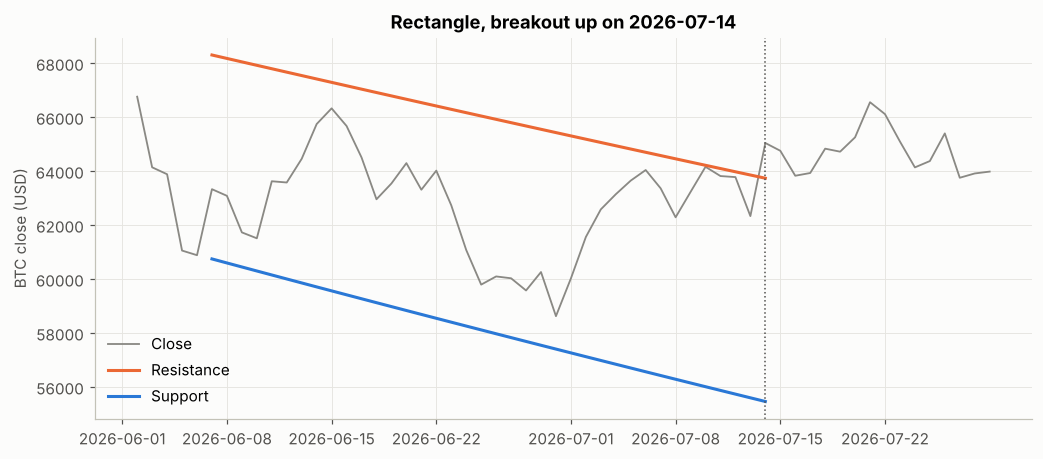

In [7]:
pats = find_triangles_wedges(np.log(daily), 30, shapes=PARALLEL_SHAPES)
rects = [p for p in pats if p.shape == 'rectangle' and daily.index[p.break_i] >= TEST_START]
p = rects[-1]
s, e = max(p.start_i - 5, 0), min(p.break_i + 15, len(daily) - 1)
idx = daily.index[s:e + 1]
x = np.arange(p.break_i - p.start_i + 1)
lines_idx = daily.index[p.start_i:p.break_i + 1]
fig, ax = plt.subplots()
ax.plot(idx, daily['close'].iloc[s:e + 1], color=GRAY, lw=1.2, label='Close')
ax.plot(lines_idx, np.exp(p.resist_intercept + p.resist_slope * x), color=ORANGE, lw=2, label='Resistance')
ax.plot(lines_idx, np.exp(p.support_intercept + p.support_slope * x), color=BLUE, lw=2, label='Support')
ax.axvline(daily.index[p.break_i], color='#52514e', ls=':', lw=1)
ax.set_title(f"Rectangle, breakout {'up' if p.direction > 0 else 'down'} on {daily.index[p.break_i].date()}")
ax.set_ylabel('BTC close (USD)')
ax.legend(frameon=False)
plt.show()

### Channel/rectangle results: daily, 5 days

In [8]:
show(sum_d, ('rectangle', 'rising_channel', 'falling_channel', 'broadening'))

,is_n,is_hit_rate,is_excess_pct,is_p_value,recent_n,recent_hit_rate,recent_excess_pct,recent_p_value,verdict
pattern,,,,,,,,,
rising_channel_up,3,1.00,10.88,0.011,1,1.00,9.81,0.025,too few
broadening_down,2,0.50,8.44,0.069,1,1.00,1.50,0.346,too few
rising_channel_down,5,0.40,0.92,0.361,5,0.40,0.09,0.477,too few
falling_channel_down,0,NaN,NaN,NaN,1,0.00,-0.53,0.578,too few
broadening_up,1,0.00,-1.21,0.604,2,0.50,-1.59,0.693,too few
rectangle_down,10,0.70,3.12,0.109,4,0.25,-2.14,0.789,too few
rectangle_up,15,0.60,6.68,0.001,6,0.17,-2.26,0.856,too few
falling_channel_up,6,0.67,1.63,0.291,0,NaN,NaN,NaN,too few


### Channel/rectangle results: hourly, 24 hours

In [9]:
show(sum_h, ('rectangle', 'rising_channel', 'falling_channel', 'broadening'))

,is_n,is_hit_rate,is_excess_pct,is_p_value,recent_n,recent_hit_rate,recent_excess_pct,recent_p_value,verdict
pattern,,,,,,,,,
rectangle_down,197,0.45,0.84,0.002,84,0.48,-0.16,0.743,faded
rectangle_up,198,0.52,0.47,0.037,89,0.45,-0.38,0.928,faded
broadening_down,36,0.31,-1.26,0.977,13,0.38,0.20,0.363,none
broadening_up,30,0.40,-0.81,0.879,20,0.50,-0.21,0.662,none
falling_channel_up,61,0.44,-0.31,0.734,34,0.35,-0.27,0.742,none
rising_channel_down,97,0.52,-0.28,0.774,45,0.42,-0.85,0.992,none
rising_channel_up,11,0.64,2.48,0.016,7,0.71,1.30,0.080,too few
falling_channel_down,4,1.00,5.83,0.005,6,0.17,-3.71,1.000,too few


## 3. PIP pattern miner (data-driven patterns)

Rather than textbook shapes, the miner:
1. takes every 24-hour window and reduces it to 5 *perceptually important points* (the shape),
2. clusters the shapes with k-means (number of clusters picked by silhouette score),
3. picks the cluster that was **best to buy** and the one **best to sell** in the training data (by Martin ratio),
4. holds each trade for 6 hours.

It is trained on **hourly data before 2024** and then run unchanged on **2024 onward**.

In [10]:
log_h = np.log(hourly['close'].to_numpy())
split = int(np.searchsorted(hourly.index, TEST_START))
miner = PIPPatternMiner(n_pips=5, lookback=24, hold_period=6)
miner.train(log_h[:split])
n_clusters = len(miner._cluster_centers)
best_long, best_short = int(miner._selected_long[0]), int(miner._selected_short[0])
print(f'{len(miner._unique_pip_patterns)} unique shapes -> {n_clusters} clusters')
print(f'Best long cluster: {best_long}   Best short cluster: {best_short}   In-sample Martin ratio: {miner.get_fit_martin():.2f}')

43.48229832928085
25402 unique shapes -> 16 clusters
Best long cluster: 8   Best short cluster: 6   In-sample Martin ratio: 43.48


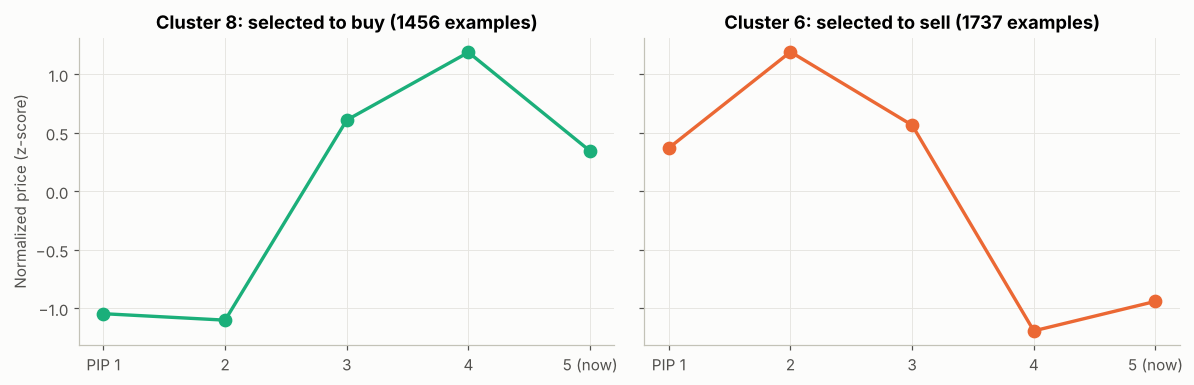

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, c, name, col in ((axs[0], best_long, 'buy', AQUA), (axs[1], best_short, 'sell', ORANGE)):
    ctr = miner._cluster_centers[c]
    ax.plot(range(5), ctr, color=col, lw=2.2, marker='o', ms=8)
    ax.set_title(f'Cluster {c}: selected to {name} ({len(miner._pip_clusters[c])} examples)')
    ax.set_xticks(range(5)); ax.set_xticklabels(['PIP 1', '2', '3', '4', '5 (now)'])
axs[0].set_ylabel('Normalized price (z-score)')
plt.tight_layout(); plt.show()

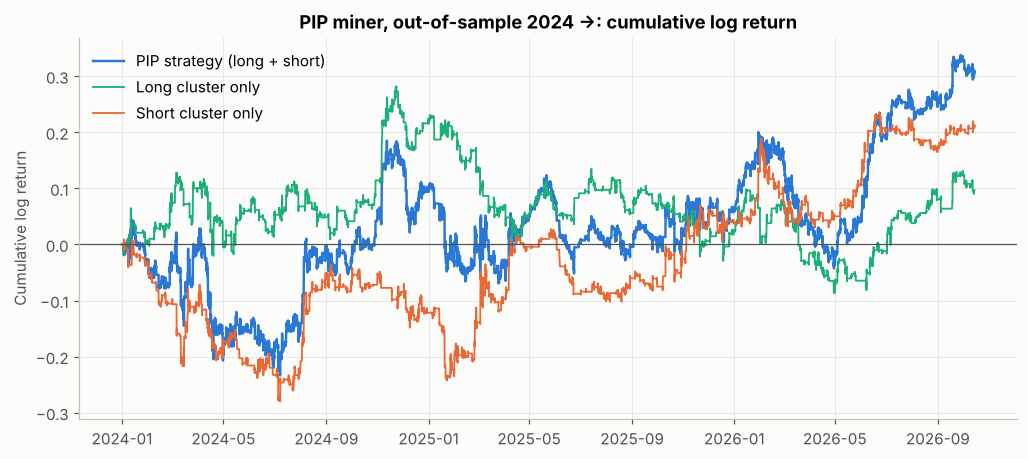

In [12]:
# Out-of-sample: assign each 2024+ bar's last-24h shape to a cluster
lookback, hold = 24, 6
cluster_at = np.full(len(log_h), -1)
for i in range(max(split, lookback - 1), len(log_h)):
    _, pips_y = find_pips(log_h[i - lookback + 1: i + 1], 5, 3)
    cluster_at[i] = miner.get_cluster(pips_y)

next_ret = np.append(np.diff(log_h), np.nan)   # return from bar i to i+1

def cluster_signal(c):
    # 1 for the `hold` bars after each bar classified as cluster c
    sig = np.zeros(len(log_h))
    for i in np.flatnonzero(cluster_at == c):
        sig[i:i + hold] = 1.0
    return sig

oos = slice(split, len(log_h) - 1)
long_sig, short_sig = cluster_signal(best_long), cluster_signal(best_short)
strat = (long_sig - short_sig) * next_ret

eq = pd.DataFrame({
    'PIP strategy (long + short)': np.nancumsum(strat[oos]),
    'Long cluster only': np.nancumsum((long_sig * next_ret)[oos]),
    'Short cluster only': np.nancumsum((-short_sig * next_ret)[oos]),
}, index=hourly.index[oos])

fig, ax = plt.subplots()
for (name, col) in zip(eq.columns, (BLUE, AQUA, ORANGE)):
    ax.plot(eq.index, eq[name], color=col, label=name, lw=1.6 if 'strategy' in name else 1.2)
ax.axhline(0, color='#52514e', lw=0.8)
ax.set_title('PIP miner, out-of-sample 2024 →: cumulative log return')
ax.set_ylabel('Cumulative log return')
ax.legend(frameon=False, loc='upper left')
plt.show()

Buy & hold log return 2024 ->: 0.654
Selected long cluster 8: OOS return 0.097, rank 9 of 16 for buying
Selected short cluster 6: OOS long return -0.211, rank 3 of 16 for selling
Strategy total OOS log return: 0.308  (time in market: 31%)
Position changes: 1663 -> fees at 0.1%/side cost 1.663; return after fees: -1.355


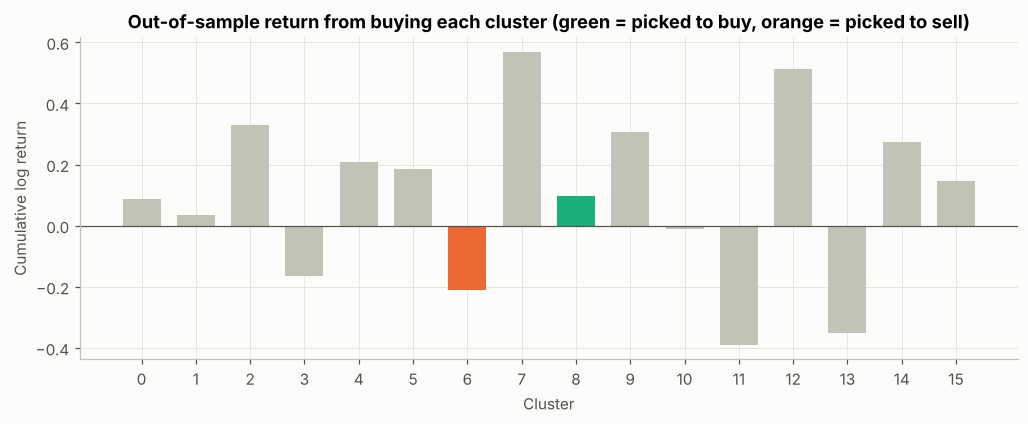

In [13]:
# Was the selected cluster special? Compare every cluster's out-of-sample return when traded long
per_cluster = []
for c in range(n_clusters):
    r = (cluster_signal(c) * next_ret)[oos]
    per_cluster.append({'cluster': c, 'oos_long_return': np.nansum(r), 'bars_in_market': int((cluster_signal(c)[oos] > 0).sum())})
pc = pd.DataFrame(per_cluster).set_index('cluster')
buy_hold = np.nansum(next_ret[oos])

rank_long = int((pc['oos_long_return'] > pc.loc[best_long, 'oos_long_return']).sum()) + 1
rank_short = int((pc['oos_long_return'] < pc.loc[best_short, 'oos_long_return']).sum()) + 1
print(f'Buy & hold log return 2024 ->: {buy_hold:.3f}')
print(f'Selected long cluster {best_long}: OOS return {pc.loc[best_long, "oos_long_return"]:.3f}, rank {rank_long} of {n_clusters} for buying')
print(f'Selected short cluster {best_short}: OOS long return {pc.loc[best_short, "oos_long_return"]:.3f}, rank {rank_short} of {n_clusters} for selling')
position = (long_sig - short_sig)[oos]
turnover = np.abs(np.diff(position, prepend=0)).sum()   # units of position changed
fee = 0.001                                             # 0.1% per side (Binance spot taker)
print(f'Strategy total OOS log return: {np.nansum(strat[oos]):.3f}  (time in market: {(np.abs(position) > 0).mean():.0%})')
print(f'Position changes: {turnover:.0f} -> fees at 0.1%/side cost {turnover * fee:.3f}; return after fees: {np.nansum(strat[oos]) - turnover * fee:.3f}')

colors = [AQUA if c == best_long else ORANGE if c == best_short else '#c3c2b7' for c in pc.index]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(pc.index.astype(str), pc['oos_long_return'], color=colors, width=0.7)
ax.axhline(0, color='#52514e', lw=0.8)
ax.set_title('Out-of-sample return from buying each cluster (green = picked to buy, orange = picked to sell)')
ax.set_xlabel('Cluster'); ax.set_ylabel('Cumulative log return')
plt.show()

## 4. Scoreboard: all patterns, earlier vs recent

Each dot is one pattern. **x** = excess return before 2024, **y** = excess return from 2024 on. Patterns in the **top-right** beat random in both periods.
Dots are sized by number of recent signals; only patterns with ≥8 signals in each period are shown, and the `edge holds` ones are labelled.

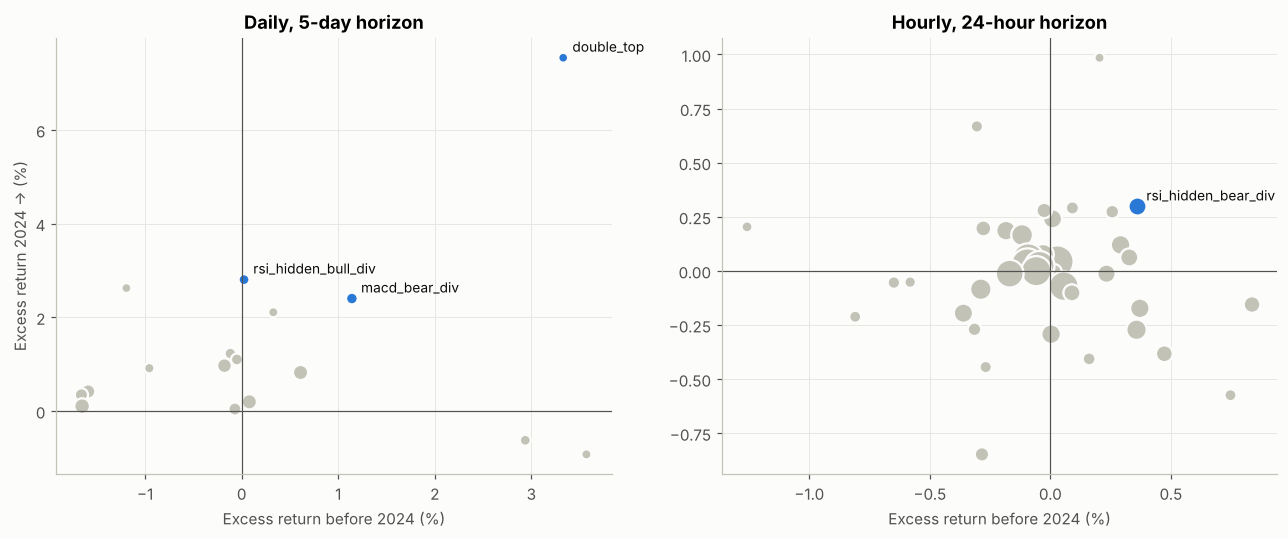

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, s, title in ((axs[0], sum_d, 'Daily, 5-day horizon'), (axs[1], sum_h, 'Hourly, 24-hour horizon')):
    s = s[(s['is_n'] >= 8) & (s['recent_n'] >= 8)]
    holds = s['verdict'] == 'edge holds'
    ax.axhline(0, color='#52514e', lw=0.8); ax.axvline(0, color='#52514e', lw=0.8)
    ax.scatter(s.loc[~holds, 'is_excess_pct'], s.loc[~holds, 'recent_excess_pct'],
               s=8 + 2 * np.sqrt(s.loc[~holds, 'recent_n']) * 6, color='#c3c2b7', edgecolor='#fcfcfb', lw=1.5)
    ax.scatter(s.loc[holds, 'is_excess_pct'], s.loc[holds, 'recent_excess_pct'],
               s=8 + 2 * np.sqrt(s.loc[holds, 'recent_n']) * 6, color=BLUE, edgecolor='#fcfcfb', lw=1.5)
    for name, row in s[holds].iterrows():
        ax.annotate(name, (row['is_excess_pct'], row['recent_excess_pct']), xytext=(6, 4),
                    textcoords='offset points', fontsize=9, color='#0b0b0b')
    ax.set_title(title); ax.set_xlabel('Excess return before 2024 (%)')
axs[0].set_ylabel('Excess return 2024 → (%)')
plt.tight_layout(); plt.show()

### Patterns where the edge holds or is weak, at every horizon

In [15]:
def horizon_table(res, names):
    t = res[res['pattern'].isin(names)].pivot_table(index=['pattern', 'period'], columns='horizon', values='excess_pct')
    return t.round(2)

good_d = sum_d.index[sum_d['verdict'].isin(['edge holds', 'weak'])]
good_h = sum_h.index[sum_h['verdict'].isin(['edge holds', 'weak'])]
print('DAILY: excess % by horizon (days)')
display(horizon_table(res_d, good_d))
print('HOURLY: excess % by horizon (hours)')
display(horizon_table(res_h, good_h))

DAILY: excess % by horizon (days)


horizon                          1     5     10    20
pattern             period                           
bearish_engulfing   in_sample  0.07  0.61  0.18  0.82
                    recent     0.14  0.82  0.88  0.33
bullish_engulfing   in_sample  0.16  0.08  1.12  2.16
                    recent    -0.37  0.20  0.76  1.43
double_top          in_sample  0.69  3.33  3.73  1.45
                    recent     0.85  7.54  5.36  6.97
macd_bear_div       in_sample  0.16  1.14  0.66 -0.36
                    recent    -0.27  2.40  2.27  5.98
rsi_bear_div        in_sample -0.20  0.33 -1.14 -3.02
                    recent    -0.46  2.11  2.00  5.74
rsi_hidden_bull_div in_sample -0.51  0.02 -1.55  0.22
                    recent     1.15  2.81  1.22  0.76

HOURLY: excess % by horizon (hours)


horizon                             6     24    72    168
pattern                 period                           
ascending_triangle_down in_sample  0.23  0.33  0.68  1.29
                        recent     0.08  0.06  0.61  0.52
bear_flag               in_sample  0.32  0.09  0.06 -0.59
                        recent    -0.31  0.29 -0.66 -0.10
bull_flag               in_sample  0.21  0.26  0.26 -0.02
                        recent    -0.13  0.27  0.20 -0.31
bull_pennant            in_sample -0.05  0.20 -0.33  2.60
                        recent     0.26  0.98  1.26  3.05
bullish_engulfing       in_sample -0.06  0.01  0.02 -0.11
                        recent     0.02  0.04  0.10  0.12
doji_bear               in_sample  0.01  0.03 -0.19 -0.43
                        recent     0.04  0.04  0.08 -0.08
rsi_hidden_bear_div     in_sample  0.02  0.36  0.40  0.66
                        recent     0.17  0.30  0.05  0.28
rsi_hidden_bull_div     in_sample -0.11  0.01  0.73  1.35
                        recent     0.02  0.24  0.46  0.39
three_white_soldiers    in_sample  0.08  0.29  0.74  0.90
                        recent    -0.01  0.12  0.30  0.37

## Conclusions

**1. Divergences: the most promising new family, mainly on daily bars.**
- Daily `macd_bear_div` and `rsi_hidden_bull_div` beat random entries in both periods (recent excess ≈ +2.4% and +2.8% over 5 days, p ≈ 0.03).
- Daily bearish divergences (`macd_bear_div`, `rsi_bear_div`) were positive at every horizon after 2024, reaching about +6% at 20 days.
- Caveat: their pre-2024 edge was small or not significant. Most of the evidence comes from 2024 onward, with only 9–18 signals.
- Hourly `rsi_hidden_bear_div` is the only hourly pattern that holds (+0.3% per 24h in both periods). That is thin once you subtract ~0.2% round-trip fees.

**2. Rectangles, channels and broadening formations: no usable edge.**
- Hourly rectangle breakouts worked before 2024 (p = 0.002 down, 0.04 up) but stopped working from 2024 on.
- Channels and broadening formations never beat random entries.
- On daily bars, each of these has fewer than 8 recent signals, so there isn't enough data to judge.

**3. PIP pattern miner: the shape selection partly carries over, but fees destroy it.**
- Trained on 2018–2023, it gained +0.31 log return from 2024 on while in the market 31% of the time (buy & hold: +0.65).
- The *sell* cluster it chose was the 3rd-worst of 16 clusters to buy after 2024, so that selection generalized. The *buy* cluster was middle of the pack (9th of 16).
- It changes position ~1,660 times. At 0.1% per side that costs ~1.66, leaving **−1.36 after fees**. It is not tradable as-is on hourly bars.

**Overall.** Most textbook patterns perform no better than random entries on BTC. The leads worth following are **daily bearish divergences (MACD/RSI)**, **daily RSI hidden bullish divergence**, and the **daily double top**. Each has few signals and was tested alongside ~45 other patterns, so some may be luck. Confirm them on other coins (ETH, SOL) before trusting any.